<a href="https://colab.research.google.com/github/siddho5971-source/Customer-Churn-analysis/blob/main/Customer_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

In [4]:
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Make column names consistent
df.columns = df.columns.str.strip()

# Check duplicate customer IDs
print("Duplicate IDs:", df["customerID"].duplicated().sum())

# Remove duplicate customer records if any exist
df = df.drop_duplicates(subset="customerID")

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values before filling
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify the cleaned data
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)

display(df.head())



Duplicate IDs: 0

Missing values before cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
Tota

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Customer Churn KPI Analysis

total_customers = df["customerID"].nunique()

churned_customers = (df["Churn"] == "Yes").sum()
retained_customers = (df["Churn"] == "No").sum()

churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

avg_tenure = df["tenure"].mean()
avg_monthly_charges = df["MonthlyCharges"].mean()

print("=" * 40)
print("       CUSTOMER CHURN KPI REPORT")
print("=" * 40)

print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churned_customers}")
print(f"Retained Customers: {retained_customers}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")
print(f"Average Tenure: {avg_tenure:.2f} months")
print(f"Average Monthly Charges: ${avg_monthly_charges:.2f}")

print("=" * 40)

       CUSTOMER CHURN KPI REPORT
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%
Retention Rate: 73.46%
Average Tenure: 32.37 months
Average Monthly Charges: $64.76


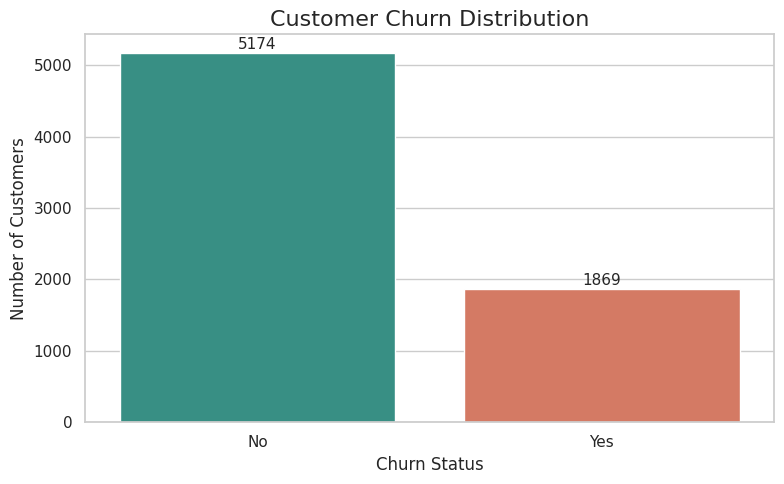

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count customers by churn status
churn_counts = df["Churn"].value_counts()

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette={"No": "#2A9D8F", "Yes": "#E76F51"},
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=16)
plt.xlabel("Churn Status", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

# Display values above the bars
for i, value in enumerate(churn_counts.values):
    plt.text(i, value + 50, str(value), ha="center", fontsize=11)

plt.tight_layout()
plt.show()

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


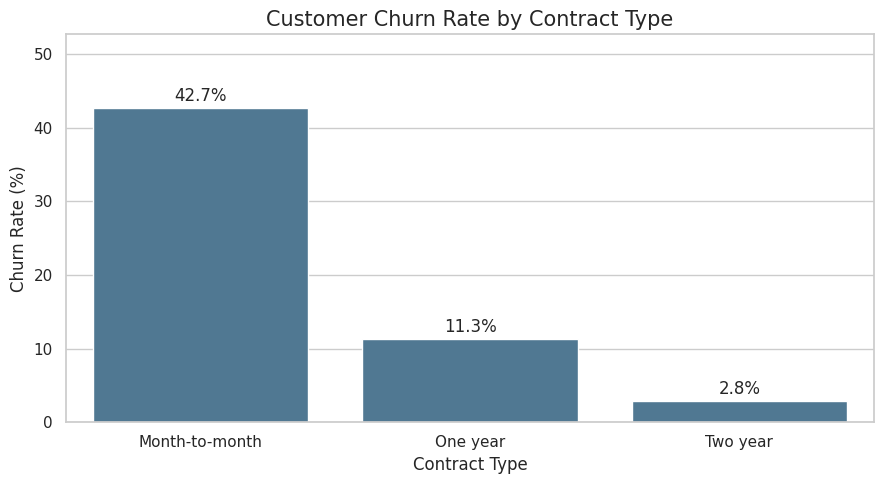

In [9]:

# Calculate churn rate by contract type

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))

# Plot the results

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values,
    color="#457B9D"
)

plt.title("Customer Churn Rate by Contract Type", fontsize=15)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(contract_churn.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, max(contract_churn.values) + 10)
plt.tight_layout()
plt.show()

### Finding 2: Churn by Contract Type

The analysis compares customer churn rates across month-to-month, one-year, and two-year contracts.

**Key observation:** Month-to-month contracts have the highest churn rate at 42.71%, followed by one-year contracts at 11.27%. Two-year contracts have the lowest churn rate at 2.83%.

**Business recommendation:** The company should investigate why month-to-month customers are more likely to leave. Targeted retention offers, proactive customer support, and incentives to switch to longer-term contracts could help improve customer retention.

### Finding 3: Churn by Customer Tenure

The analysis compares customer churn rates across four tenure groups: 0–12 months, 13–24 months, 25–48 months, and 49–72 months.

**Key observation:** Customers with 0–12 months of tenure have the highest churn rate at 47.44%, followed by customers with 13–24 months at 28.71%, 25–48 months at 20.39%, and 49–72 months at 9.51%. This indicates that churn rates are highest among newer customers and generally decline as tenure increases.

**Business recommendation:** The company should focus on improving the early customer experience through onboarding support, regular follow-ups, and proactive resolution of service issues. Targeted retention campaigns during the first year could help reduce early customer churn.

### Finding 4: Churn by Payment Method

The analysis compares customer churn rates across different payment methods.

**Key observation:** Customers who use electronic checks have the highest churn rate at **45.29%**. Customers who use automatic bank transfers have a churn rate of **16.71%**, while those using automatic credit card payments have the lowest churn rate at **15.24%**.

**Business recommendation:** The company should investigate why electronic-check customers are more likely to leave. It could offer convenient automatic payment options, provide clearer billing information, and contact at-risk customers to understand their concerns.

### Finding 5: Churn by Monthly Charges

The analysis compares the monthly charges of customers who churned with those who stayed.

**Key observation:** Customers who churned had an average monthly charge of **74.44**, compared with **61.27** for customers who stayed. This suggests that customers paying higher monthly charges were more likely to churn.

**Business recommendation:** The company should review pricing and provide suitable plans or targeted offers to customers with high monthly charges. It should also investigate whether these customers receive sufficient value from their services.


Churn Rate by Tenure Group:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


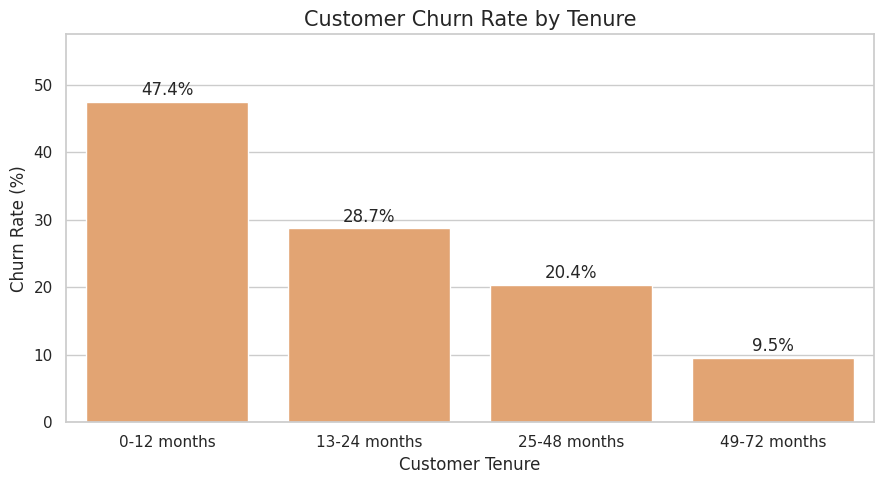

In [11]:
#Create a new code cell and run this:

# Group customers by tenure
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

# Calculate churn rate in each group
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn Rate by Tenure Group:")
print(tenure_churn.round(2))

# Create chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=tenure_churn.index.astype(str),
    y=tenure_churn.values,
    color="#F4A261"
)

plt.title("Customer Churn Rate by Tenure", fontsize=15)
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(tenure_churn.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, max(tenure_churn.values) + 10)
plt.tight_layout()
plt.show()

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


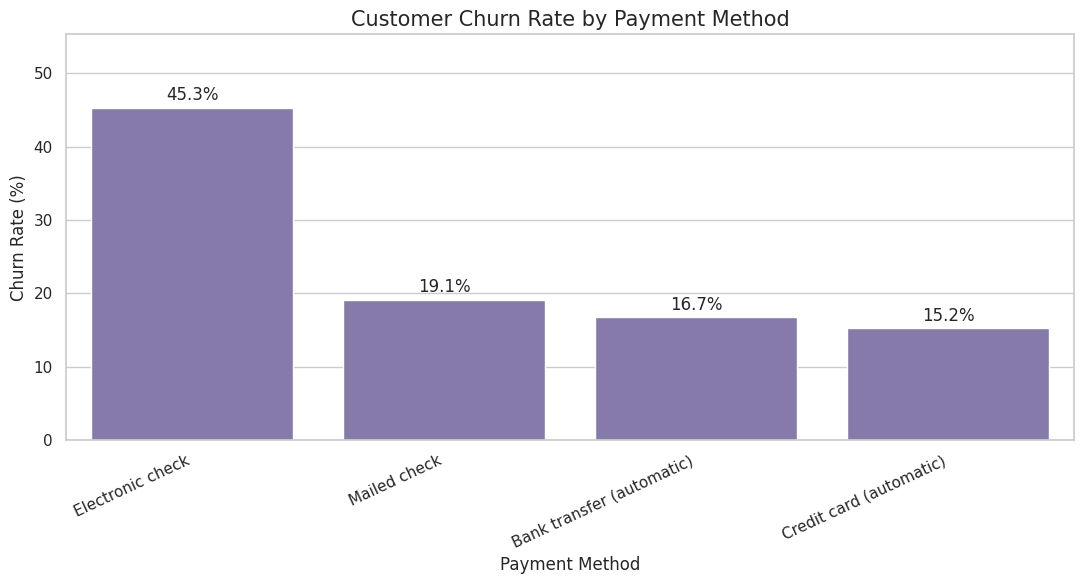

In [12]:
#Add a new code cell in Google Colab and run this code:
# Calculate churn rate by payment method

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Payment Method:")
print(payment_churn.round(2))

# Create the chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values,
    color="#8172B2"
)

plt.title("Customer Churn Rate by Payment Method", fontsize=15)
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")

for i, value in enumerate(payment_churn.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, max(payment_churn.values) + 10)
plt.tight_layout()
plt.show()

Monthly Charges by Churn Status:


,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869


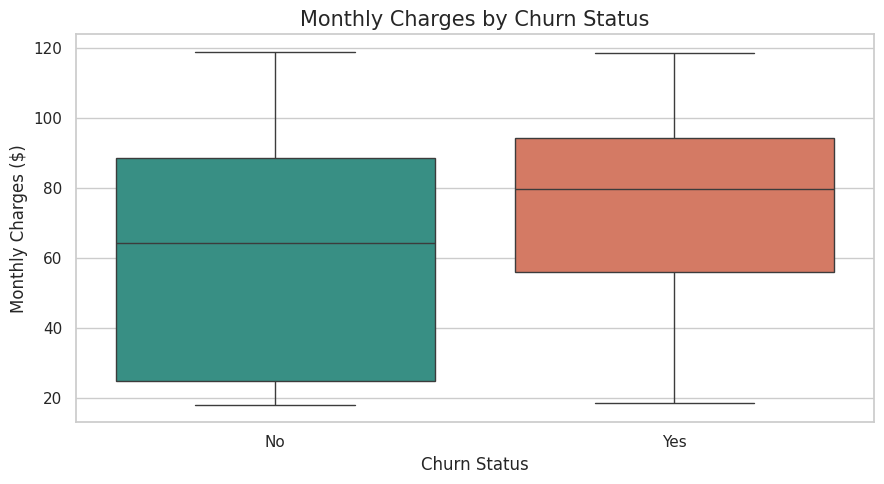

In [13]:
# Compare average monthly charges by churn status

charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

print("Monthly Charges by Churn Status:")
display(charges_summary.round(2))

# Visualize the distribution
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "#2A9D8F", "Yes": "#E76F51"},
    legend=False
)

plt.title("Monthly Charges by Churn Status", fontsize=15)
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.show()

In [14]:

# CUSTOMER CHURN ANALYSIS - KEY BUSINESS INSIGHTS

# 1. Churn rate by contract type
contract_summary = (
    df.groupby("Contract", observed=False)["Churn"]
    .agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )
)

contract_summary["Churn_Rate_%"] = (
    contract_summary["Churned_Customers"]
    / contract_summary["Total_Customers"] * 100
)

print("1. CHURN BY CONTRACT TYPE")
display(contract_summary.round(2).sort_values(
    "Churn_Rate_%", ascending=False
))

# 2. Churn rate by payment method
payment_summary = (
    df.groupby("PaymentMethod", observed=False)["Churn"]
    .agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )
)

payment_summary["Churn_Rate_%"] = (
    payment_summary["Churned_Customers"]
    / payment_summary["Total_Customers"] * 100
)

print("\n2. CHURN BY PAYMENT METHOD")
display(payment_summary.round(2).sort_values(
    "Churn_Rate_%", ascending=False
))

# 3. Monthly charges by churn status
print("\n3. MONTHLY CHARGES BY CHURN STATUS")
display(
    df.groupby("Churn", observed=False)["MonthlyCharges"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 4. Tenure by churn status
print("\n4. TENURE BY CHURN STATUS")
display(
    df.groupby("Churn", observed=False)["tenure"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 5. Overall churn percentage
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall customer churn rate: {churn_rate:.2f}%")


1. CHURN BY CONTRACT TYPE


,Total_Customers,Churned_Customers,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



2. CHURN BY PAYMENT METHOD


,Total_Customers,Churned_Customers,Churn_Rate_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24



3. MONTHLY CHARGES BY CHURN STATUS


,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869



4. TENURE BY CHURN STATUS


,mean,median,count
Churn,,,
No,37.57,38.0,5174
Yes,17.98,10.0,1869



Overall customer churn rate: 26.54%


In [15]:

# Verify records with blank TotalCharges in the original dataset

raw_df = pd.read_csv(url)

blank_charges = raw_df[
    raw_df["TotalCharges"].astype(str).str.strip().eq("")
]

print("Records with blank TotalCharges:", len(blank_charges))

display(
    blank_charges[["customerID", "tenure", "TotalCharges"]]
)


Records with blank TotalCharges: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [16]:

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing TotalCharges records
missing_charges = df["TotalCharges"].isna()

print("Missing TotalCharges:", missing_charges.sum())
print(
    "Missing records with zero tenure:",
    (missing_charges & (df["tenure"] == 0)).sum()
)

# Fill missing charges with zero for zero-tenure customers
df.loc[
    missing_charges & (df["tenure"] == 0),
    "TotalCharges"
] = 0

# Verify remaining missing values
print(
    "Remaining missing TotalCharges:",
    df["TotalCharges"].isna().sum()
)


Missing TotalCharges: 0
Missing records with zero tenure: 0
Remaining missing TotalCharges: 0


In [17]:

print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

print(
    "Zero-tenure customers:",
    (df["tenure"] == 0).sum()
)

print(
    "Zero-tenure customers with zero charges:",
    ((df["tenure"] == 0) & (df["TotalCharges"] == 0)).sum()
)


Missing TotalCharges: 0
Zero-tenure customers: 11
Zero-tenure customers with zero charges: 11


In [18]:

print("Churn Rate by Tenure Group:")
print(tenure_churn.round(2))


Churn Rate by Tenure Group:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


## Conclusion

This project analyzed customer churn using the IBM Telco Customer Churn dataset, which contains 7,043 customer records.

The overall customer churn rate was **26.54%**, meaning that approximately one in four customers had left the company.

The analysis revealed several important patterns:

- **Contract type:** Month-to-month customers had the highest churn rate at 42.71%.
- **Customer tenure:** Customers with 0–12 months of tenure had the highest churn rate at 47.44%.
- **Payment method:** Customers paying by electronic check had the highest churn rate at 45.29%.
- **Monthly charges:** Customers who churned had higher average monthly charges than customers who stayed.

These findings suggest that the company should focus on early customer retention, investigate the reasons behind higher churn among month-to-month and electronic-check customers, and review the value offered to customers paying higher monthly charges.

Overall, this project demonstrates how data cleaning, exploratory data analysis (EDA), visualization, and business recommendations can help identify customer churn patterns and support data-driven decision-making.